In [1]:
# Project paths: run Jupyter from this repository or a notebook subdirectory.
# Saved outputs are from the original archive; they have not been recomputed.
from pathlib import Path
import os

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data" / "random_numbers.npz").is_file()), None
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter inside the monsoon_bias_MAP24 repository.")
DATA_DIR = Path(os.environ.get("PRECIP_DATA_DIR", str(PROJECT_ROOT / "data"))).expanduser()
WEIGHTS_DIR = Path(os.environ.get("PRECIP_WEIGHTS_DIR", str(PROJECT_ROOT / "models"))).expanduser()
RESULTS_DIR = PROJECT_ROOT / "results"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import h5py
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, GlobalAveragePooling1D, LSTM, Dense
from tensorflow.keras.layers import Dropout, Input, Add,  Conv2DTranspose, Reshape
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
import matplotlib.pyplot as plt
import os
import random
import xarray as xr
import pickle
from sklearn.preprocessing import StandardScaler
import dask
import dask.dataframe as dd
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras import layers, models
from dask.distributed import Client
client = Client()

/panfs/ccds02/app/modules/anaconda/platform/x86_64/rhel/8.6/3-2022.05/envs/earthml/lib/python3.8/site-packages/distributed/node.py:151: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 37091 instead
  warnings.warn(


In [2]:
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

In [3]:
data=np.load(str(DATA_DIR / "ml_data_pr.npz"))
X=data['X']
Y=data['Y']
nx=len(data['lon'])
ny=len(data['lat'])

lon=(data['lon'])
lat=(data['lat'])
date=(data['date'])

In [4]:
# import random
# random_numbers = random.sample(range(0, (len(X))),len(X))

In [5]:
#np.savez(str(PROJECT_ROOT / "data" / "random_numbers.npz"),random_numbers=random_numbers)
random_numbers=np.load(str(PROJECT_ROOT / "data" / "random_numbers.npz"))['random_numbers']

In [6]:
X=X[random_numbers,:,:,:]
Y=Y[random_numbers,:,:,:]
date=date[random_numbers]

In [7]:
# xmean = X.mean()
# xstd = X.std()

# # Normalize the data
# normalized_X = (X - xmean) / xstd



# ymean = Y.mean()
# ystd = Y.std()

# # Normalize the data
# normalized_Y = (Y - ymean) / ystd


In [8]:
normalized_Y=Y
normalized_X=X

In [9]:
nf = 3  # number of input features
nv = 2  # number of variables to be forecasted
nx = 101  # spatial dimension width
ny = 91   # spatial dimension height

# Define the input shape
input_shape = (ny, nx, nf)

model = models.Sequential()

# First convolutional layer with 32 filters, 3x3 kernel size
model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape))
model.add(layers.BatchNormalization())  # Helps in normalizing the activations and gradients

# Second convolutional layer with 64 filters, 3x3 kernel size
model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Additional convolutional layer with 128 filters
model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Final layer to produce the output with `nv` channels
model.add(layers.Conv2D(nv, (1, 1), activation='linear', padding='same'))

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Display the model summary
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 91, 101, 32)       896       
_________________________________________________________________
batch_normalization (BatchNo (None, 91, 101, 32)       128       
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 91, 101, 64)       18496     
_________________________________________________________________
batch_normalization_1 (Batch (None, 91, 101, 64)       256       
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 91, 101, 128)      73856     
_________________________________________________________________
batch_normalization_2 (Batch (None, 91, 101, 128)      512       
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 91, 101, 2)        2

In [10]:
X_norm_train=normalized_X[0:500,:,:,:]
Y_norm_train=normalized_Y[0:500,:,:,:]

In [11]:
X_norm_test=normalized_X[500:,:,:,:]
Y_norm_test=normalized_Y[500:,:,:,:]

In [12]:
model_weights_path = str(WEIGHTS_DIR / "best_model_weights.h5")
try:
    model.load_weights(model_weights_path)
    print("Loaded weights from previous model!")
except:
    print("No previous weights found, starting from scratch.")

Loaded weights from previous model!


In [13]:

    

checkpoint = ModelCheckpoint(model_weights_path, save_best_only=True, save_weights_only=True, monitor='val_loss', mode='min', verbose=1)

history = model.fit(X_norm_train, Y_norm_train, epochs=500, batch_size=16, validation_split=.15, callbacks=[checkpoint])

Epoch 1/500
27/27 [==============================] - ETA: 0s - loss: 9.3609
Epoch 00001: val_loss improved from inf to 9.43889, saving model to /home/afahad/nb/precip_SA/best_model_weights.h5
27/27 [==============================] - 24s 889ms/step - loss: 9.3609 - val_loss: 9.4389
Epoch 2/500
25/27 [==========================>...] - ETA: 0s - loss: 9.1718
Epoch 00002: val_loss did not improve from 9.43889
27/27 [==============================] - 0s 14ms/step - loss: 9.1545 - val_loss: 9.4996
Epoch 3/500
24/27 [=========================>....] - ETA: 0s - loss: 9.2881
Epoch 00003: val_loss improved from 9.43889 to 9.39283, saving model to /home/afahad/nb/precip_SA/best_model_weights.h5
27/27 [==============================] - 0s 14ms/step - loss: 9.2893 - val_loss: 9.3928
Epoch 4/500
23/27 [========================>.....] - ETA: 0s - loss: 9.2604
Epoch 00004: val_loss did not improve from 9.39283
27/27 [==============================] - 0s 13ms/step - loss: 9.2368 - val_loss: 9.4090
Epoc

In [14]:
# load best model

model.load_weights(str(WEIGHTS_DIR / "best_model_weights.h5"))

In [15]:
#testing

#Test

Yp_norm_test = model.predict(X_norm_test)

In [16]:
# # 1. Load the saved scaler for Y from the pickle file
# # 4. Reshape back to original 5D shape
# original_Yp = Yp_norm_test * ystd + ymean
# original_Y = Y_norm_test * ystd + ymean

# original_X = X_norm_test * xstd + xmean

In [17]:
# 1. Load the saved scaler for Y from the pickle file
# 4. Reshape back to original 5D shape
original_Yp = Yp_norm_test# * ystd + ymean
original_Y = Y_norm_test #* ystd + ymean

original_X = X_norm_test# * xstd + xmean

In [18]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

#fig = plt.figure(figsize=(11, 8.5))

# Create an axes with the PlateCarree projection

def plot(data,lon,lat,cmap='coolwarm',fig=[],nx=[],ny=[],sub=[1,1,1],clf=[],frac=.004):

    ax = fig.add_subplot(sub[0], sub[1], sub[2], projection=ccrs.PlateCarree())

    # Example usage of the axes
    ax.coastlines()  # Adds coastlines
    try:
        ax.set_extent([nx[0], nx[1], ny[0], ny[1]]) # define the boundary
    except:
        None

    try:
        cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both',levels=clf)
    except:
                cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both')

    plt.colorbar(cc,orientation='horizontal',  shrink=5,pad=0.1,fraction=frac)
    gl = ax.gridlines(draw_labels=True, linewidth=0.01)

    gl.xlabels_top = False  # Disable labels on the top
    gl.ylabels_right = False  # Disable labels on the right
    gl.xformatter = ccrs.cartopy.mpl.gridliner.LONGITUDE_FORMATTER
    gl.yformatter = ccrs.cartopy.mpl.gridliner.LATITUDE_FORMATTER

    return(ax)
#map5.contourf(lon,lat,Yp_norm_test[nn,:,:,1])


In [27]:
rmse=np.sqrt(np.mean((original_Yp[:,:,:,1]-original_Y[:,:,:,1])**2,0))
rmse2=np.sqrt(np.mean((original_X[:,:,:,2]-original_Y[:,:,:,1])**2,0))

corr=np.zeros(rmse.shape)
corr2=np.zeros(rmse.shape)

for i in range(91):
    for j in range(101):
        corr[i,j]=np.corrcoef(original_Yp[:,:,:,1][:,i,j],original_Y[:,:,:,1][:,i,j])[0,1]
        corr2[i,j]=np.corrcoef(original_X[:,:,:,2][:,i,j],original_Y[:,:,:,1][:,i,j])[0,1]

Text(0.5, 1.0, 'GEOS-S2S-3 + ML')

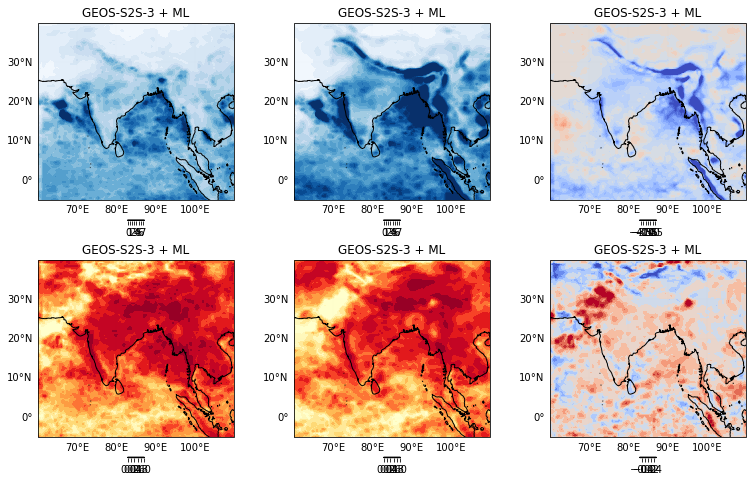

In [29]:
        fig=plt.figure(figsize=(13,8))
        clf=np.arange(0,8,.5)
        cmap='Blues'
        plot(rmse,lon,lat,cmap=cmap,sub=[2,3,1],clf=clf,fig=fig)
        plt.title('GEOS-S2S-3 + ML')
        plot(rmse2,lon,lat,cmap=cmap,sub=[2,3,2],clf=clf,fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        clf=np.arange(-5,5.1,.5)
        cmap='coolwarm'
        plot(rmse-rmse2,lon,lat,cmap=cmap,sub=[2,3,3],clf=clf,fig=fig)
        plt.title('GEOS-S2S-3 + ML')
        
        clf=np.arange(0,1.1,.1)
        cmap='YlOrRd'
        plot(corr,lon,lat,cmap=cmap,sub=[2,3,4],clf=clf,fig=fig)
        plt.title('GEOS-S2S-3 + ML')
        plot(corr2,lon,lat,cmap=cmap,sub=[2,3,5],clf=clf,fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        clf=np.arange(-.5,.51,.1)
        cmap='coolwarm'
        plot(corr-corr2,lon,lat,cmap=cmap,sub=[2,3,6],clf=clf,fig=fig)
        plt.title('GEOS-S2S-3 + ML')

/panfs/ccds02/app/modules/anaconda/platform/x86_64/rhel/8.6/3-2022.05/envs/earthml/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/panfs/ccds02/app/modules/anaconda/platform/x86_64/rhel/8.6/3-2022.05/envs/earthml/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


Text(0.5, 0.98, '1 months lead mean')

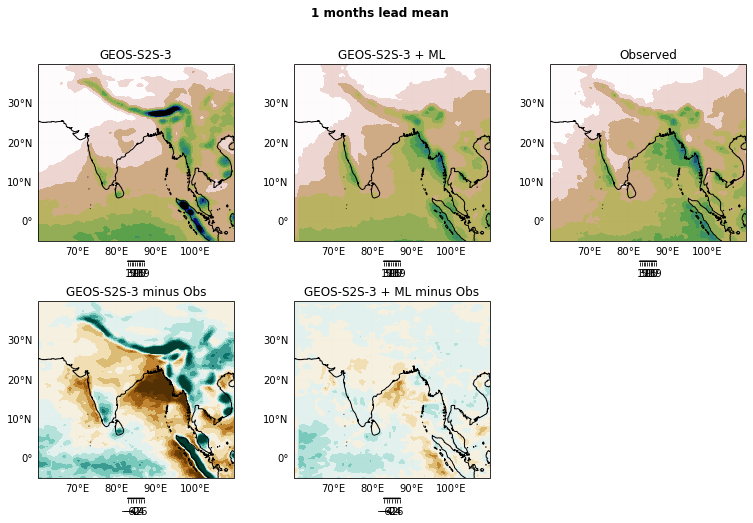

In [19]:
clf=np.arange(1,21,2)
cmap='gist_earth_r'

nn=34
l=0
fig=plt.figure(figsize=(13,8))

plot(np.nanmean(original_Yp[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
plt.title('GEOS-S2S-3 + ML')

plot(np.nanmean(original_X[:,:,:,l+1],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
plt.title('GEOS-S2S-3')

plot(np.nanmean(original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
plt.title('Observed')

clf=np.arange(-6,6.1,1)
cmap='BrBG'


plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
plt.title('GEOS-S2S-3 + ML minus Obs')

plot(np.nanmean(original_X[:,:,:,l+1]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
plt.title('GEOS-S2S-3 minus Obs')
plt.suptitle(str(l+1)+' months lead mean',fontsize=12,fontweight='bold')


Text(0.5, 0.98, '2 months lead mean')

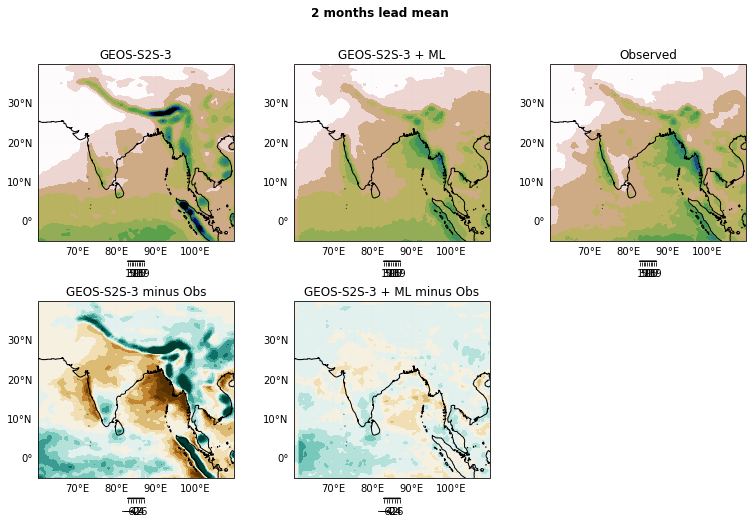

In [20]:
clf=np.arange(1,21,2)
cmap='gist_earth_r'

nn=34
l=1
fig=plt.figure(figsize=(13,8))

plot(np.nanmean(original_Yp[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
plt.title('GEOS-S2S-3 + ML')

plot(np.nanmean(original_X[:,:,:,l+1],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
plt.title('GEOS-S2S-3')

plot(np.nanmean(original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
plt.title('Observed')

clf=np.arange(-6,6.1,1)
cmap='BrBG'


plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
plt.title('GEOS-S2S-3 + ML minus Obs')

plot(np.nanmean(original_X[:,:,:,l+1]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
plt.title('GEOS-S2S-3 minus Obs')
plt.suptitle(str(l+1)+' months lead mean',fontsize=12,fontweight='bold')

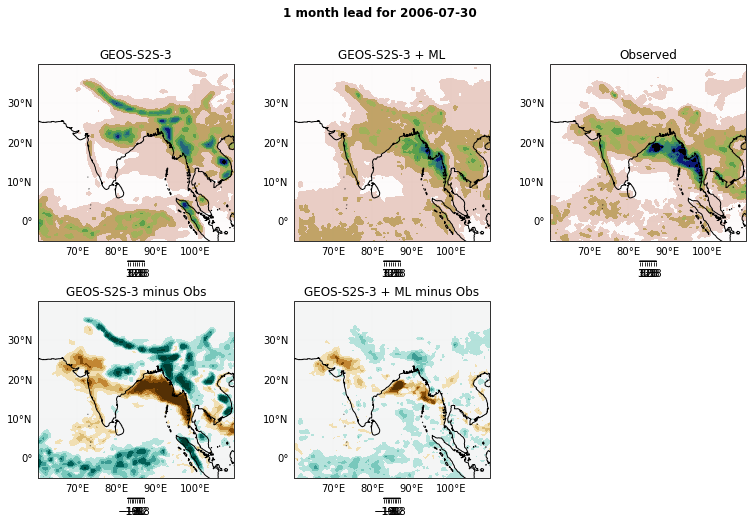

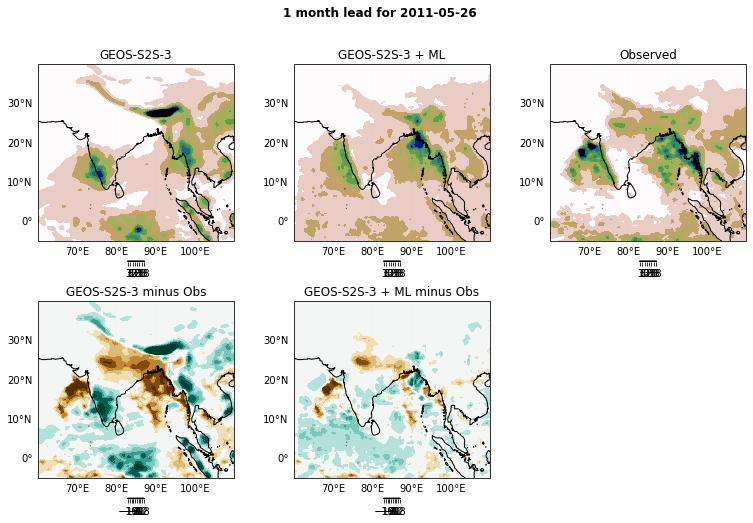

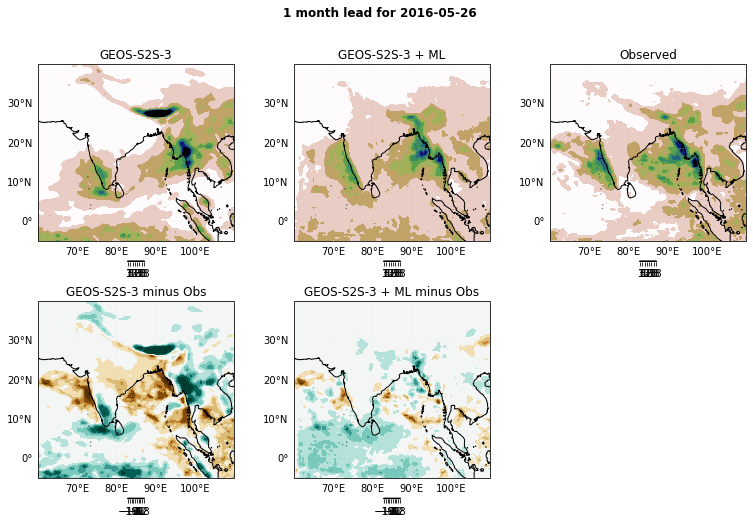

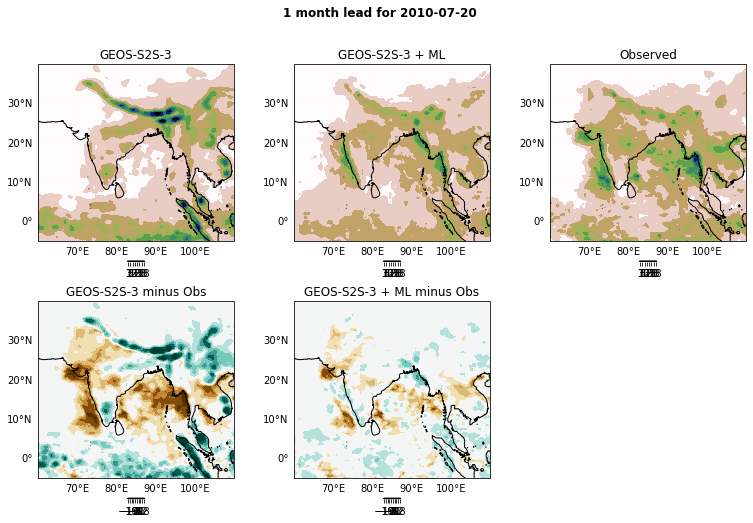

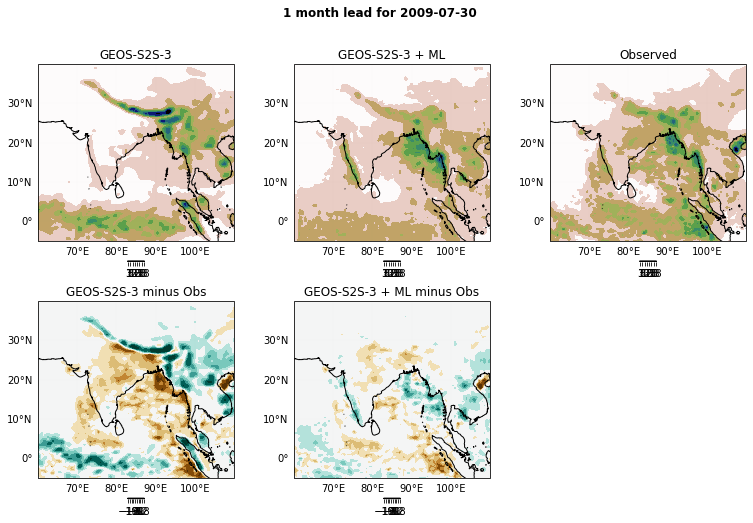

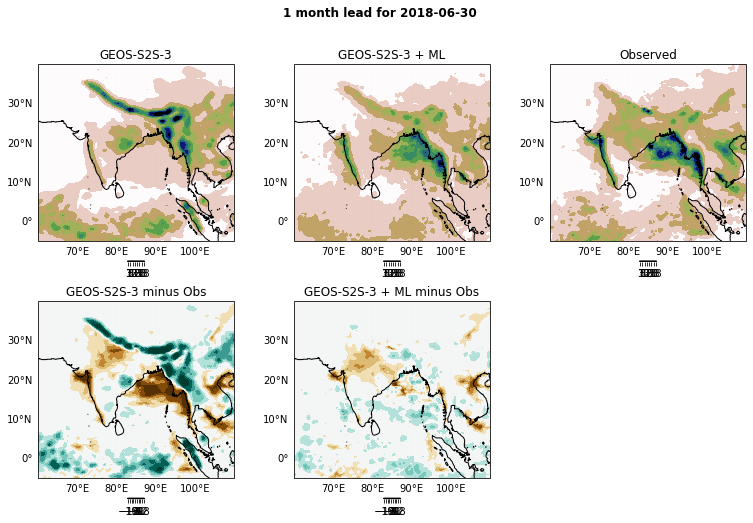

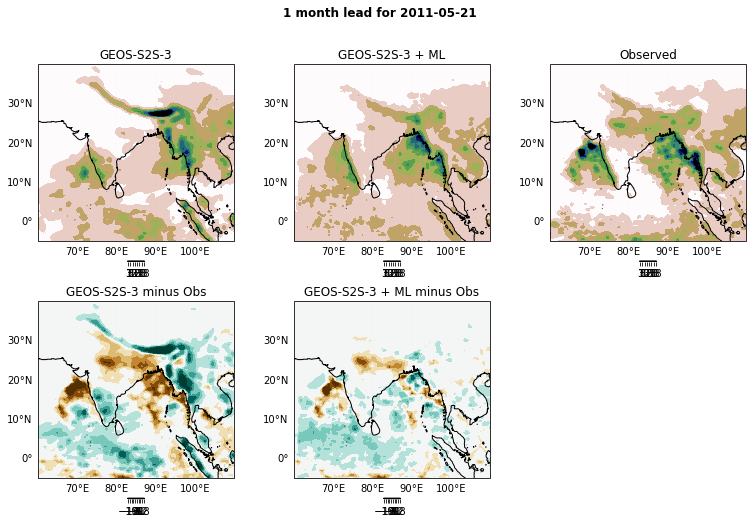

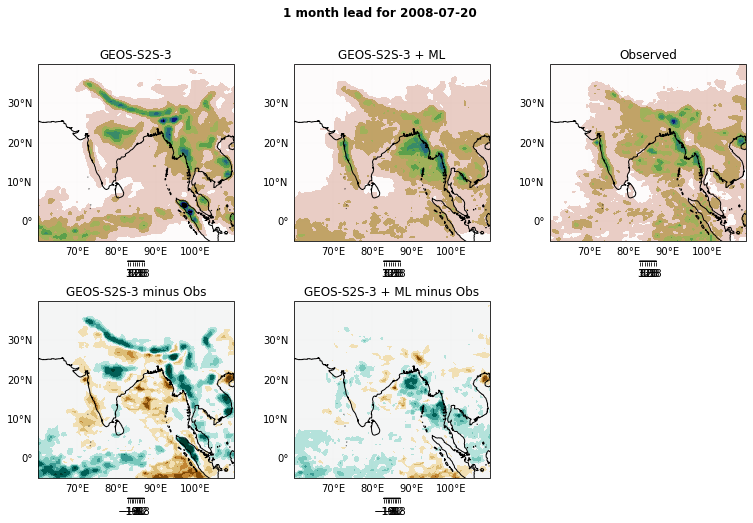

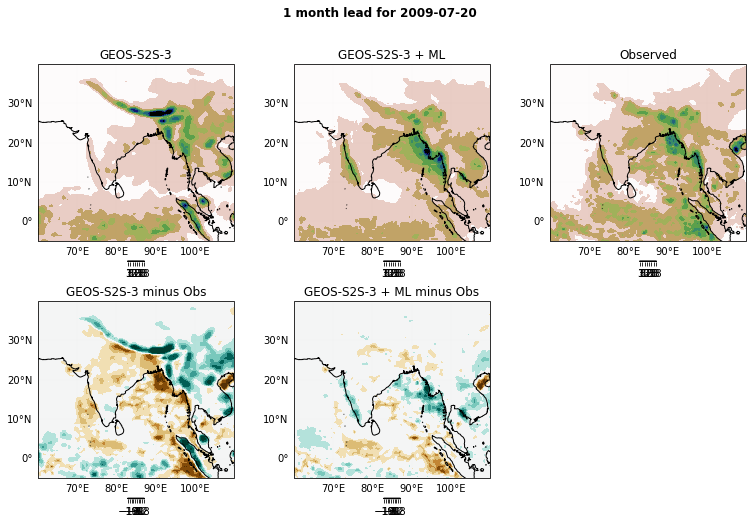

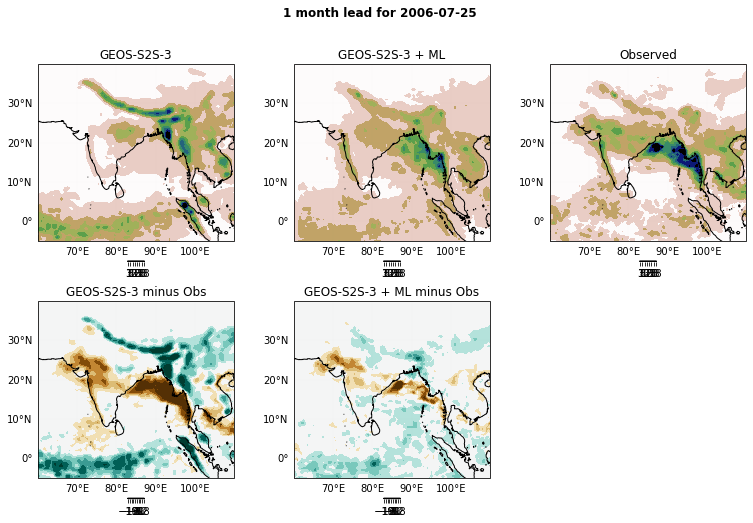

distributed.nanny - WARNING - Restarting worker


Error in callback <function flush_figures at 0x1520387d0dc0> (for post_execute):


distributed.nanny - WARNING - Restarting worker
distributed.nanny - WARNING - Restarting worker
distributed.nanny - WARNING - Restarting worker
distributed.nanny - WARNING - Restarting worker


KeyboardInterrupt: 

In [21]:
for i in range(39):
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):

        nn=i
        l=0
        fig=plt.figure(figsize=(13,8))
        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('GEOS-S2S-3')

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('Observed')

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('GEOS-S2S-3 + ML minus Obs')

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('GEOS-S2S-3 minus Obs')
        plt.suptitle(str(l+1)+' month lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
    else:
        None

0
1
2
7
9
14
18
22
23
28
29
32
34
35


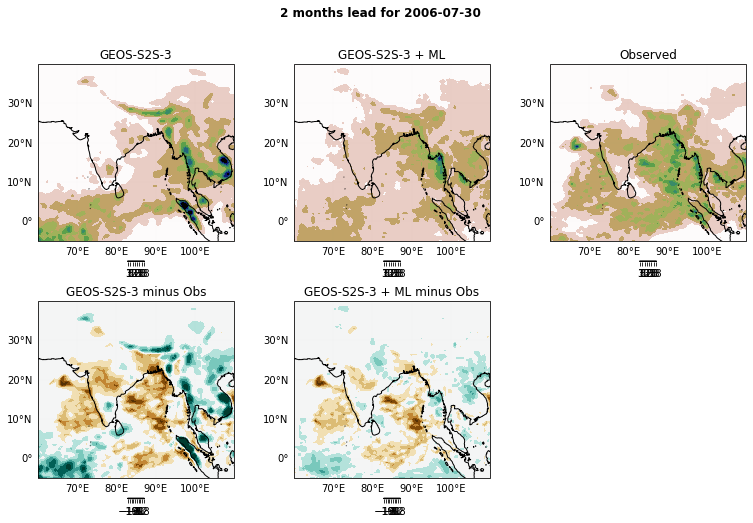

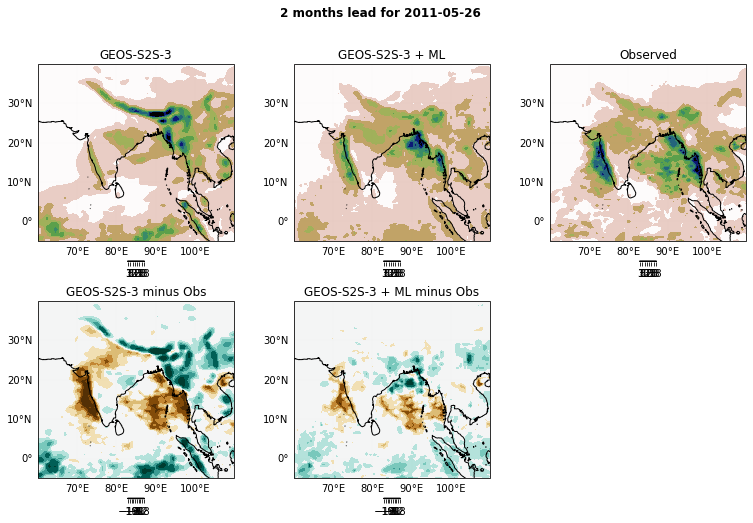

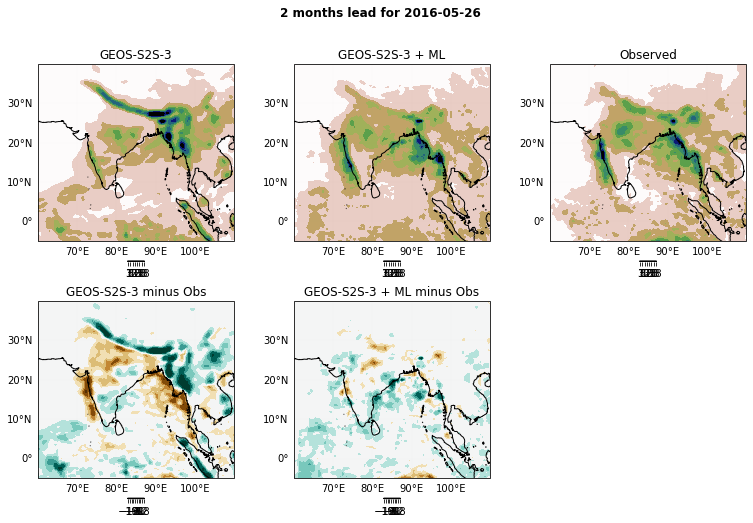

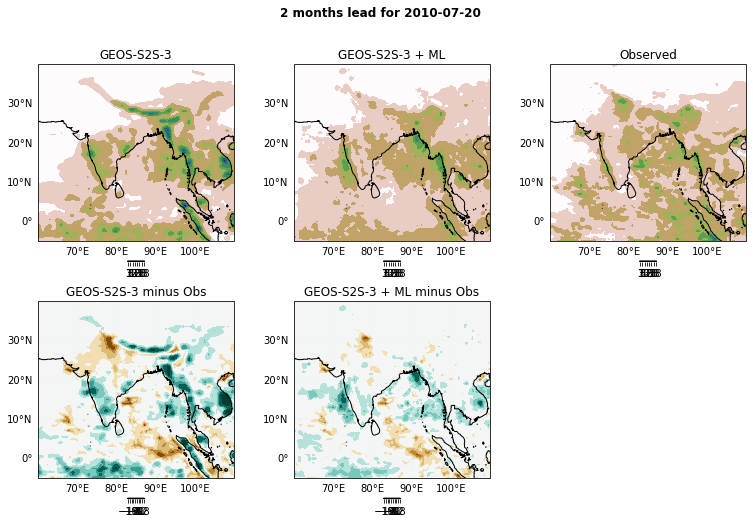

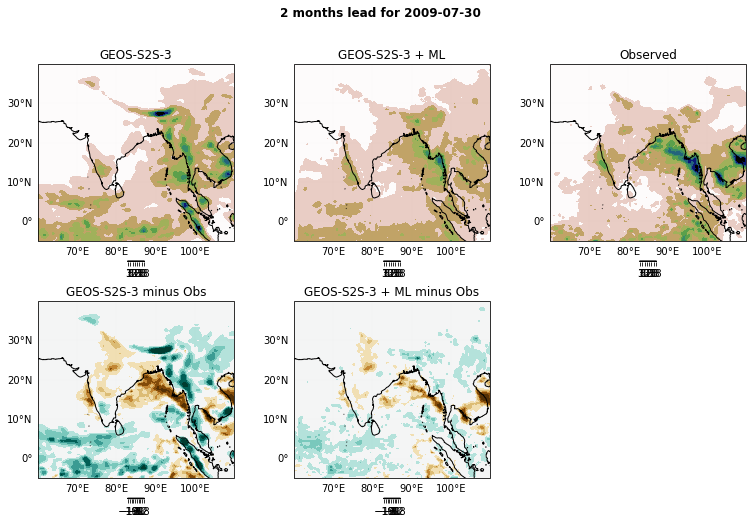

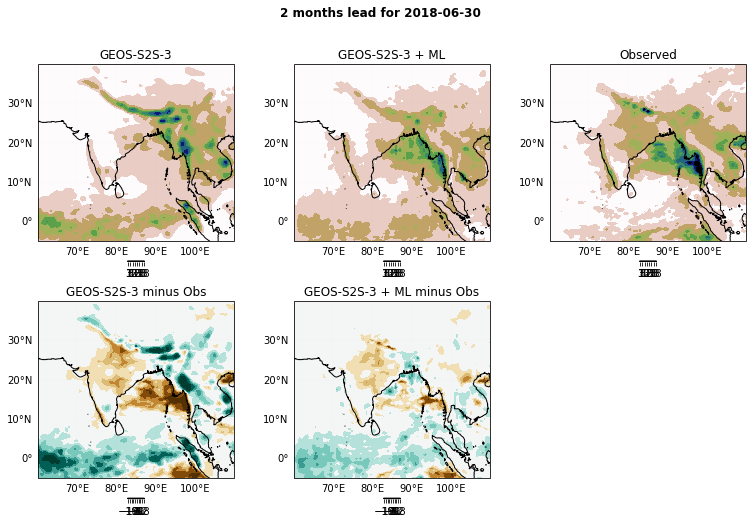

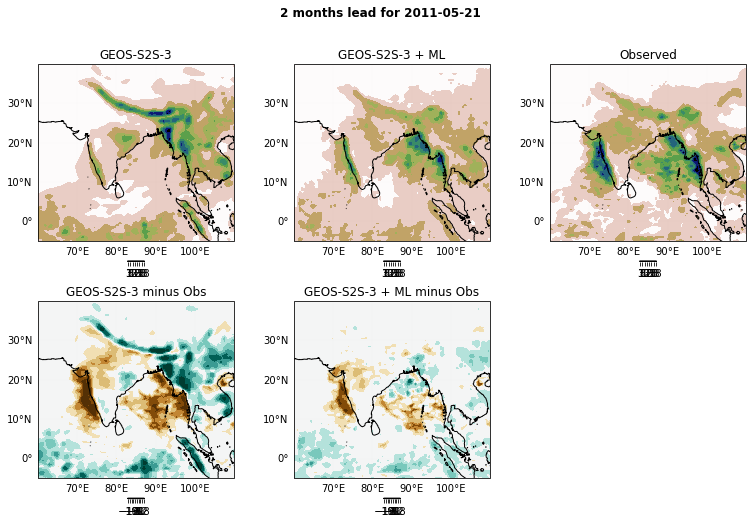

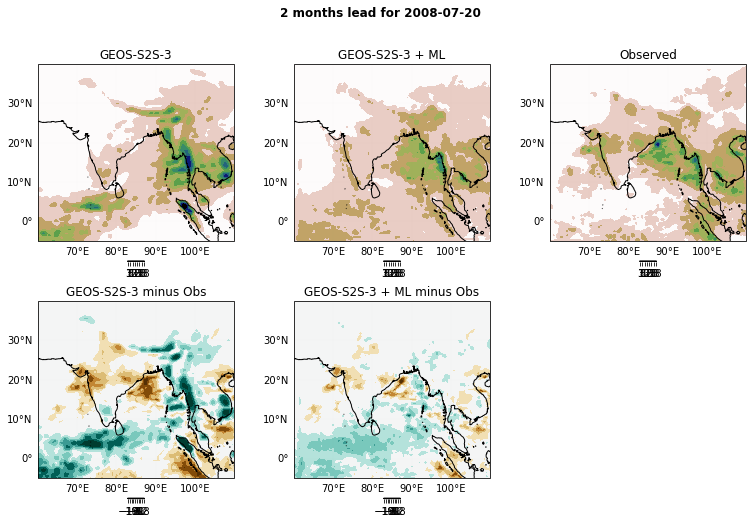

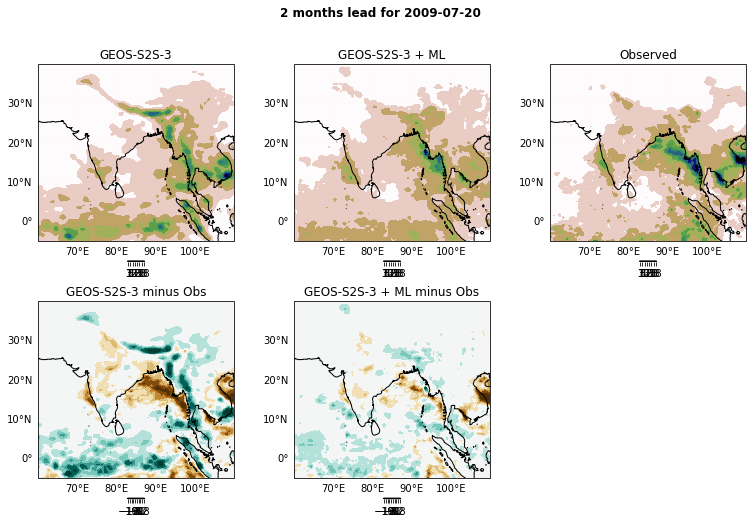

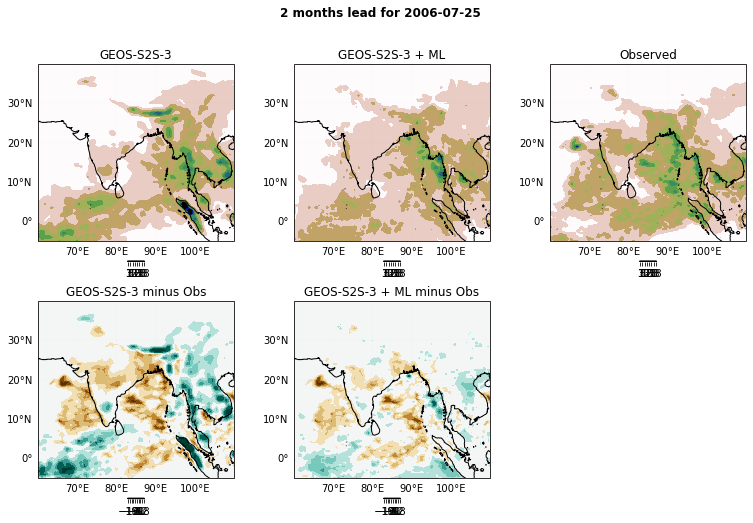

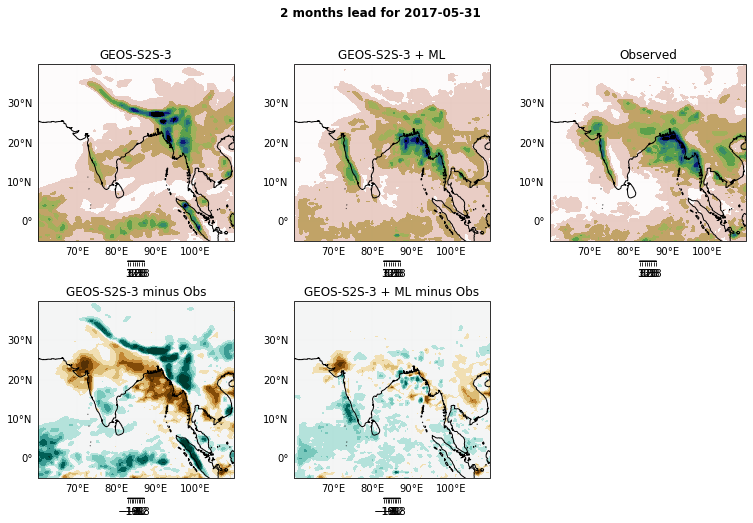

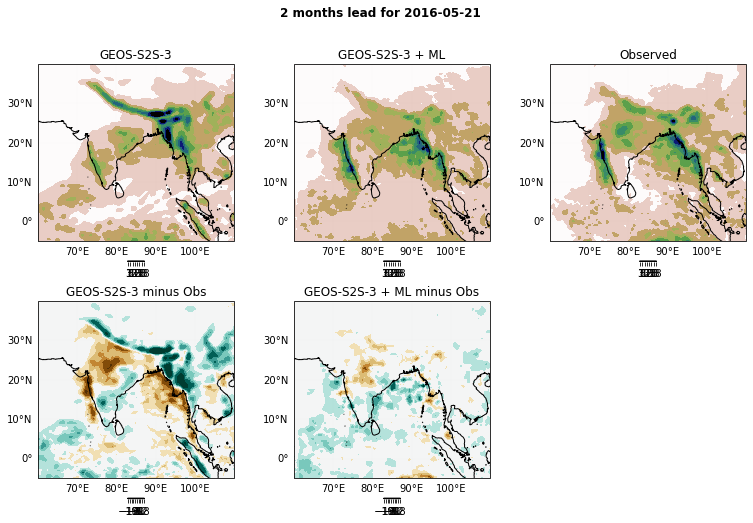

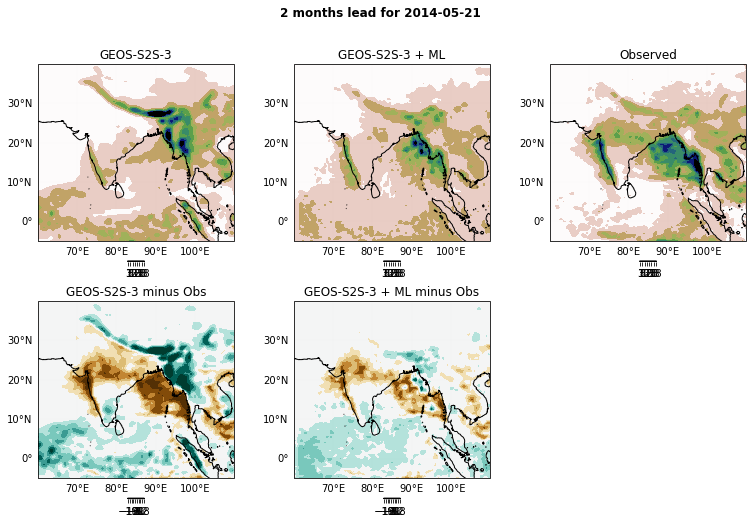

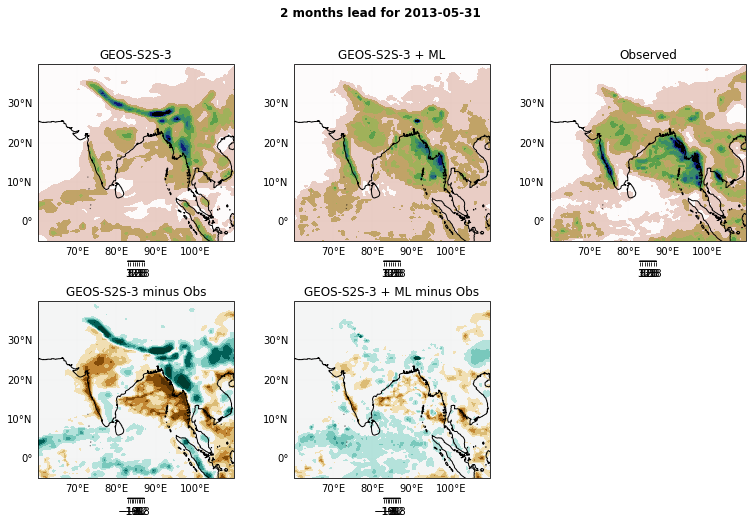

In [22]:


for i in range(36):
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(13,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('GEOS-S2S-3')

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('Observed')

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('GEOS-S2S-3 + ML minus Obs')

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('GEOS-S2S-3 minus Obs')
        plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')

2


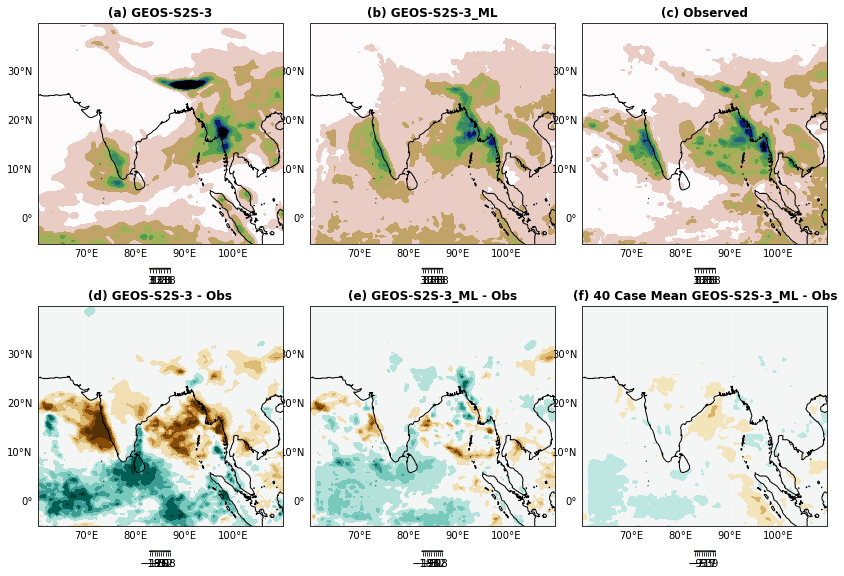

In [23]:
    i=2
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=0

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(11.5,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('(b) GEOS-S2S-3_ML',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('(a) GEOS-S2S-3',fontweight='bold', fontsize=12)

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('(c) Observed',fontweight='bold', fontsize=12)

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('(e) GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('(d) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)

        plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=np.arange(-9,9.1,2),sub=[2,3,6],fig=fig)
        plt.title('(f) 40 Case Mean GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)
        
        plt.tight_layout()
        #plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
        #plt.savefig(str(RESULTS_DIR / "GEOSML.png"),dpi=200)

In [24]:
sal=np.load(str(DATA_DIR / "sal.npz"))['sal']

2


NameError: name 'lon1' is not defined

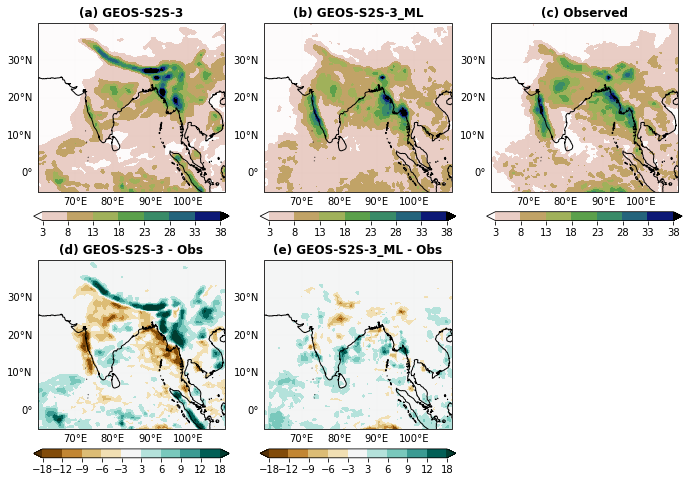

In [23]:
    i=2
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(11.5,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('(b) GEOS-S2S-3_ML',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('(a) GEOS-S2S-3',fontweight='bold', fontsize=12)

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('(c) Observed',fontweight='bold', fontsize=12)

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('(e) GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('(d) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)

        # plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=np.arange(-9,9.1,2),sub=[2,3,6],fig=fig)
        # plt.title('(f) 40 Case Mean GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(sal,lon1,lat1,cmap=cmap,sub=[2,3,6],fig=fig)
        plt.title('(f) 40 Case Mean GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)
        
        plt.tight_layout()
        #plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
        #plt.savefig(str(RESULTS_DIR / "GEOSML.png"),dpi=200)

In [19]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

#fig = plt.figure(figsize=(11, 8.5))

# Create an axes with the PlateCarree projection

def plot(data,lon,lat,cmap='coolwarm',fig=[],nx=[],ny=[],sub=[1,1,1],clf=[],frac=.045):

    ax = fig.add_subplot(sub[0], sub[1], sub[2], projection=ccrs.PlateCarree())

    # Example usage of the axes
    ax.coastlines()  # Adds coastlines
    try:
        ax.set_extent([nx[0], nx[1], ny[0], ny[1]]) # define the boundary
    except:
        None

    try:
        cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both',levels=clf)
    except:
                cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both')

    plt.colorbar(cc,orientation='horizontal',  shrink=5,pad=0.1,fraction=frac)
    gl = ax.gridlines(draw_labels=True, linewidth=0.01)

    gl.xlabels_top = False  # Disable labels on the top
    gl.ylabels_right = False  # Disable labels on the right
    gl.xformatter = ccrs.cartopy.mpl.gridliner.LONGITUDE_FORMATTER
    gl.yformatter = ccrs.cartopy.mpl.gridliner.LATITUDE_FORMATTER

    return(ax)
#map5.contourf(lon,lat,Yp_norm_test[nn,:,:,1])


In [48]:
X_sample=original_X.astype(np.float32)
X_sample = tf.convert_to_tensor(X_sample, dtype=tf.float32)
# Using GradientTape to calculate the saliency map
with tf.GradientTape() as tape:
    # Watch the input tensor
    tape.watch(X_sample)

    # Predict with the model
    predictions = model(X_sample)

    # Assume we are interested in the mean of the predictions (customize your loss appropriately)
    loss = tf.reduce_mean(predictions)

# Compute gradients of the loss w.r.t the input image
grads = tape.gradient(loss, X_sample)

# Normalize the gradients
normalized_grads = grads / (tf.sqrt(tf.reduce_mean(tf.square(grads))) + 1e-5)

In [60]:
saliency_map = normalized_grads.numpy()

<GeoAxesSubplot:>

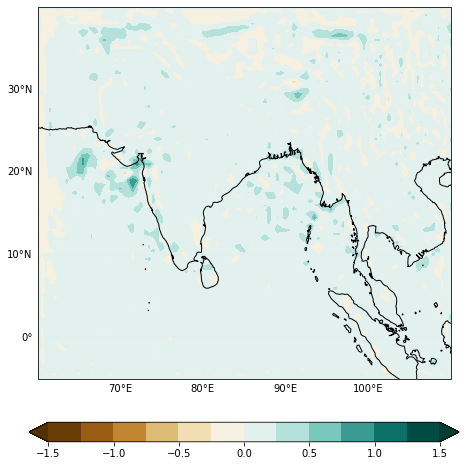

In [76]:
fig=plt.figure(figsize=(11.5,8))

plot(np.nanmean(saliency_map[:,:,:,2],0),lon,lat,clf=np.arange(-1.5,1.51,.25),cmap=cmap,sub=[1,1,1],fig=fig)